# VS code cũng đẹp mà
Tui yêu cái đẹp, thấy cái gì đẹp là tui lưu lại hết à
Tui muốn sản phẩm mk làm ra có sự chỉnh chu, áp dụng được vào thực tiễn, thực sự có ích cho đời

In [2]:
# import libraries 

import numpy as np
import pandas as pd
import unicodedata
import re


#Vẽ biểu đồ
import matplotlib.pyplot as plt 

# Vẽ biểu đồ nhiệt
import seaborn as sns

from collections import Counter

# 1. ETL Basic Statisctic

In [2]:
# review file data
filename = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\Crawl_job\Data_raw\data_careerviet.csv"

df=pd.read_csv(filename)
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,salary,experience,level_employee,education_level,description,requirements,benefits,source_site
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Nhân viên chính thức,28 Tr - 40 Tr VND,3 - 5 Năm,Nhân viên,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Nhân viên chính thức,Cạnh tranh,Trên 5 Năm,Nhân viên,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Nhân viên chính thức,Cạnh tranh,Trên 3 Năm,Nhân viên,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Nhân viên chính thức,Cạnh tranh,Trên 3 Năm,Nhân viên,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Nhân viên chính thức,Cạnh tranh,Trên 1 Năm,Nhân viên,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Nhân viên chính thức,15 Tr - 25 Tr VND,Chưa có kinh nghiệm,Nhân viên,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Nhân viên chính thức,18 Tr - 25 Tr VND,2 - 4 Năm,Nhân viên,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Nhân viên chính thức,Cạnh tranh,2 - 3 Năm,Nhân viên,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phần mề

## 1. ĐỔI TÊN CỘT

### 1.1 Thêm cột "source" cho data, mặc định `4` nghĩa là `careerviet`

In [3]:
df['source'] = "4"

### 1.2 Đổi tên các cột khác sau khi ETL hàng loạt

In [3]:
# review file data
filename_3 = r"data_crviet_3.csv"

df=pd.read_csv(filename_3)
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,...,experience,education_level,description,requirements,benefits,source_site,source,job_position,min_experience,mean_salary
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,2026-03-27,2026-04-25,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,...,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0,34000000.0
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-20,2026-05-04,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0,NaN
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-10,2026-05-09,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,NaN
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-03,2026-05-02,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,NaN
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,2026-04-13,2026-05-12,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,...,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,2026-06-11,2026-07-11,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,...,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,0.0,20000000.0
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,2026-06-11,2026-07-11,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,...,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,2.0,21500000.0
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,2026-06-10,2026-07-10,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,...,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên,2.0,NaN
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,2026-06-12,2026-07-31,"CNTT - Phần mềm , CNTT - Phần cứng / 

In [4]:
df.rename(columns={
    'posted_date'    : 'date_posted',
    'deadline_date'  : 'date_deadline',
    'education_level': 'edu'
    
}, inplace=True)

df.head(5)

,index,job_url,search_keyword,job_title,company_name,location,date_posted,date_deadline,category,work_type,...,experience,edu,description,requirements,benefits,source_site,source,job_position,min_experience,mean_salary
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,2026-03-27,2026-04-25,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,...,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0,34000000.0
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-20,2026-05-04,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0,NaN
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-10,2026-05-09,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,NaN
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-03,2026-05-02,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,NaN
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,2026-04-13,2026-05-12,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,...,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0,NaN


### 1.3 Xóa các cột ko cần nữa

In [5]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['experience', 'salary'])
df

,index,job_url,search_keyword,job_title,company_name,location,date_posted,date_deadline,category,work_type,edu,description,requirements,benefits,source_site,source,job_position,min_experience,mean_salary
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,2026-03-27,2026-04-25,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0,34000000.0
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-20,2026-05-04,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0,NaN
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-10,2026-05-09,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,NaN
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,2026-04-03,2026-05-02,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,NaN
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,2026-04-13,2026-05-12,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,2026-06-11,2026-07-11,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,0.0,20000000.0
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,2026-06-11,2026-07-11,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,2.0,21500000.0
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,2026-06-10,2026-07-10,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên,2.0,NaN
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,2026-06-12,2026-07-31,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng , Sả...",Full-time,NaN,Summary:. Motivated Software Developer and res...,"REQUIRED KNOWLEDGE, SKILLS AND ABILITIES:. Wor...",Laptop. Chế độ bảo hiểm. Du Lịc

In [6]:
## 2. SAVED lần 4
## Lần này xong hẳn rồi nhá, chờ ghép thôi
df.to_csv("data_crviet_4.csv", index=False, encoding="utf-8-sig")

# 2. ELT các cột

## 2.1. Cột hình thức làm việc

In [5]:
df['work_type'].value_counts()

work_type
Nhân viên chính thức                    874
Thực tập                                 25
Nhân viên chính thức , Thực tập           8
Nhân viên chính thức , Bán thời gian      4
Bán thời gian , Thực tập                  2
Thời vụ/ Nghề tự do                       1
Name: count, dtype: int64

In [6]:

# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
job_mapping = {
    'nhân viên chính thức , bán thời gian': 'Part-time',
    'bán thời gian , thực tập': 'Part-time',
    'thời vụ/ nghề tự do': 'Part-time',
    
    'nhân viên chính thức , thực tập': 'Full-time',
    'nhân viên chính thức': 'Full-time',
    'thực tập': 'Full-time',
    
    # Các mục còn lại được xếp vào nhóm 'Khác' theo yêu cầu (do dữ liệu không có Hybrid)
    'khác': 'Khác'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['work_type'] = df['work_type'].str.strip().str.lower().map(job_mapping).fillna('Khác')

# 3. Kiểm tra kết quả
df['work_type'].value_counts()


work_type
Full-time    907
Part-time      7
Khác           5
Name: count, dtype: int64

## 2.2. Địa điểm

In [7]:
def clean_vietnamese_text(text):
    """Hàm làm sạch và chuẩn hóa văn bản"""
    if pd.isna(text):
        return ""
    
    # 1. Chuyển về chữ thường
    text = str(text).lower()
    
    # 2. Loại bỏ dấu tiếng Việt (thực tập -> thuc tap)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8')
    
    # 3. Thay thế các ký tự đặc biệt (-, _) bằng khoảng trắng
    text = text.replace('-', ' ').replace('_', ' ')
    
    # 4. Xóa khoảng trắng thừa và khoảng trắng hai đầu
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text 

In [9]:
# Lấy file về location 
# đã Fix lại case [Đà Nẵng - a nang] [Nam Định - nam inh]

filename_location = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_1_vietnamworks\Location.csv"
df_location = pd.read_csv(filename_location)

df_location

,ID,location,keyword_lower
0,1,Hà Nội,ha noi
1,2,Hồ Chí Minh,ho chi minh
2,3,Đà Nẵng,a nang
3,4,Hải Phòng,hai phong
4,5,Cần Thơ,can tho
...,...,...,...
58,59,Kiên Giang,kien giang
59,60,Hậu Giang,hau giang
60,61,Sóc Trăng,soc trang
61,62,Bạc Liêu,bac lieu


In [10]:
# Sắp xếp bảng Location theo cột ID tăng dần (ID nhỏ xếp trước, ID lớn xếp sau)
df_location_sorted = df_location.sort_values(
    by=df_location.columns[0], # Cột thứ 1 (Cột ID)
    ascending=True             # True có nghĩa là nhỏ trước, lớn sau
)

# dict này sẽ tự động xếp các từ khóa theo thứ tự ID của bạn từ trên xuống dưới
city_mapping = dict(zip(df_location_sorted.iloc[:, 2], df_location_sorted.iloc[:, 1]))

city_mapping

{'ha noi': 'Hà Nội',
 'ho chi minh': 'Hồ Chí Minh',
 'a nang': 'Đà Nẵng',
 'hai phong': 'Hải Phòng',
 'can tho': 'Cần Thơ',
 'hue': 'Huế',
 'vinh phuc': 'Vĩnh Phúc',
 'bac ninh': 'Bắc Ninh',
 'quang ninh': 'Quảng Ninh',
 'hai duong': 'Hải Dương',
 'hung yen': 'Hưng Yên',
 'thai binh': 'Thái Bình',
 'ha nam': 'Hà Nam',
 'nam inh': 'Nam Định',
 'ninh binh': 'Ninh Bình',
 'ha giang': 'Hà Giang',
 'cao bang': 'Cao Bằng',
 'bac kan': 'Bắc Kạn',
 'tuyen quang': 'Tuyên Quang',
 'lao cai': 'Lào Cai',
 'yen bai': 'Yên Bái',
 'thai nguyen': 'Thái Nguyên',
 'lang son': 'Lạng Sơn',
 'bac giang': 'Bắc Giang',
 'phu tho': 'Phú Thọ',
 'ien bien': 'Điện Biên',
 'lai chau': 'Lai Châu',
 'son la': 'Sơn La',
 'hoa binh': 'Hoà Bình',
 'thanh hoa': 'Thanh Hoá',
 'nghe an': 'Nghệ An',
 'ha tinh': 'Hà Tĩnh',
 'quang binh': 'Quảng Bình',
 'quang tri': 'Quảng Trị',
 'quang nam': 'Quảng Nam',
 'quang ngai': 'Quảng Ngãi',
 'binh inh': 'Bình Định',
 'phu yen': 'Phú Yên',
 'khanh hoa': 'Khánh Hoà',
 'ninh thuan': 

In [11]:
def extract_city(location_raw):
    
    # ĐIỀU KIỆN 1: Nếu cột dữ liệu rỗng hoặc trống -> Trả về None (Null trong Pandas)
    if pd.isna(location_raw) or str(location_raw).strip() == "":
        return None
        
    # Lấy phần tử cuối cùng sau dấu phẩy (nếu có)
    city_part = str(location_raw).split(',')[-1]
    
    # Đưa qua hàm làm sạch văn bản
    cleaned_city = clean_vietnamese_text(city_part)
    
    # Nếu sau khi làm sạch mà chuỗi trống rỗng -> Trả về None
    if not cleaned_city:
        return None
        
    
    
    # ĐIỀU KIỆN 2: Nếu khớp với bảng map -> Trả về kết quả khớp
    for key_word, standard_name in city_mapping.items():
        if key_word in cleaned_city:
            return standard_name
        

    # Nếu không tìm thấy trong 63 tỉnh thành (vd: Australia, Overseas, Japan...)
    return "Nước Ngoài / Khác"


In [12]:
# Test thử:
print(extract_city('17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi')) # -> Hà Nội
print(extract_city('28 Mạc Đĩnh Chi, District 1, Ho Chi Minh City'))     # -> Hồ Chí Minh
print(extract_city('Ho Chi Minh City (remote flexibility)'))          # -> Hồ Chí Minh
print(extract_city('68 CIRCULAR ROAD #02-01 SINGAPORE (049422)'))   # -> Nước Ngoài / Khác
print(extract_city(' đà nẵng  '))   # -> Nước Ngoài / Khác

Hà Nội
Hồ Chí Minh
Hồ Chí Minh
Nước Ngoài / Khác
Đà Nẵng


In [13]:
# Chạy hàm để tạo cột mới
df['cleaned_location'] = df['location'].apply(extract_city)

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hà Nội,Hà Nội
1,Hà Nội,Hà Nội
2,Hà Nội,Hà Nội
3,Hà Nội,Hà Nội
4,Hà Nội,Hà Nội
...,...,...
914,Hà Nội,Hà Nội
915,Hà Nội,Hà Nội
916,Hồ Chí Minh,Hồ Chí Minh
917,Hồ Chí Minh,Hồ Chí Minh


In [14]:
df['cleaned_location'].value_counts()

cleaned_location
Hồ Chí Minh          418
Hà Nội               417
Đồng Nai              25
Bình Dương            20
Long An               12
Bà Rịa – Vũng Tàu      8
Tây Ninh               3
Đà Nẵng                2
Cần Thơ                2
Quảng Ngãi             2
Bình Định              1
Hưng Yên               1
Đắk Lắk                1
An Giang               1
Hải Phòng              1
Lâm Đồng               1
Name: count, dtype: int64

In [15]:
df['location'] = df['cleaned_location']

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hà Nội,Hà Nội
1,Hà Nội,Hà Nội
2,Hà Nội,Hà Nội
3,Hà Nội,Hà Nội
4,Hà Nội,Hà Nội
...,...,...
914,Hà Nội,Hà Nội
915,Hà Nội,Hà Nội
916,Hồ Chí Minh,Hồ Chí Minh
917,Hồ Chí Minh,Hồ Chí Minh


## 2.3. job_position

In [16]:
df['level_employee'].value_counts()

level_employee
Nhân viên                   713
Trưởng nhóm / Giám sát       83
Quản lý                      51
Sinh viên/ Thực tập sinh     35
Mới tốt nghiệp               18
Giám đốc                     10
Phó Giám đốc                  5
Name: count, dtype: int64

In [17]:
# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
position_mapping = {
    'nhân viên': 'Nhân viên',
    'trưởng nhóm / giám sát': 'Trưởng nhóm',
    
    'sinh viên/ thực tập sinh': 'Thực tập / Mới tốt nghiệp', 
    'mới tốt nghiệp': 'Thực tập / Mới tốt nghiệp', 
    
    'giám đốc': 'Lãnh đạo / Quản lý',
    'phó giám đốc': 'Lãnh đạo / Quản lý',
    'quản lý': 'Lãnh đạo / Quản lý',
    
    # Các mục còn lại được xếp vào nhóm 'Không đề cập' theo yêu cầu
    'không đề cập': 'Không đề cập'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['job_position'] = df['level_employee'].str.strip().str.lower().map(position_mapping).fillna('Không đề cập')

# 3. Kiểm tra kết quả
df[['level_employee', 'job_position']]


,level_employee,job_position
0,Nhân viên,Nhân viên
1,Nhân viên,Nhân viên
2,Nhân viên,Nhân viên
3,Nhân viên,Nhân viên
4,Nhân viên,Nhân viên
...,...,...
914,Nhân viên,Nhân viên
915,Nhân viên,Nhân viên
916,Nhân viên,Nhân viên
917,Nhân viên,Nhân viên


In [18]:
df['level_employee'].value_counts()

level_employee
Nhân viên                   713
Trưởng nhóm / Giám sát       83
Quản lý                      51
Sinh viên/ Thực tập sinh     35
Mới tốt nghiệp               18
Giám đốc                     10
Phó Giám đốc                  5
Name: count, dtype: int64

In [19]:
df['job_position'].value_counts()

job_position
Nhân viên                    713
Trưởng nhóm                   83
Lãnh đạo / Quản lý            66
Thực tập / Mới tốt nghiệp     53
Không đề cập                   4
Name: count, dtype: int64

In [20]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['level_employee', 'cleaned_location'])
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,salary,experience,education_level,description,requirements,benefits,source_site,source,job_position
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,28 Tr - 40 Tr VND,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,Cạnh tranh,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,15 Tr - 25 Tr VND,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,18 Tr - 25 Tr VND,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,Cạnh tranh,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng , Sả...",Full-time,Cạnh tranh,5 - 7

In [21]:
## 2. SAVED lần 1
df.to_csv("data_crviet_1.csv", index=False, encoding="utf-8-sig")

## 2.4. Experient Kinh nghiệm

In [3]:
# review file data
filename_1 = r"data_crviet_1.csv"

df=pd.read_csv(filename_1)
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,salary,experience,education_level,description,requirements,benefits,source_site,source,job_position
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,28 Tr - 40 Tr VND,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,Cạnh tranh,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,15 Tr - 25 Tr VND,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,18 Tr - 25 Tr VND,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,Cạnh tranh,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng , Sả...",Full-time,Cạnh tranh,5 - 7

In [6]:
df['experience'].value_counts()

experience
3 - 5 Năm      107
2 - 3 Năm       70
Trên 3 Năm      66
Trên 2 Năm      60
2 - 5 Năm       54
              ... 
6 - 8 Năm        1
10 - 12 Năm      1
7 - 30 Năm       1
1 - 8 Năm        1
6 - 10 Năm       1
Name: count, Length: 64, dtype: int64

In [7]:
def extract_min_experience(text):
    # 1. Giá trị missing value / None thì cứ để None
    if pd.isna(text) or text is None:
        return None
        
    text_lower = str(text).lower()
    
    # 2. Những giá trị được quy định mặc định là "0"
    if re.search(r'không yêu cầu kinh nghiệm|chưa có kinh nghiệm|null - null năm', text_lower):
        return 0

        
    # 3. Tìm tất cả các số có trong chuỗi
    numbers = re.findall(r'\d+', text_lower)
    
    # Nếu có số, ép kiểu sang int và lấy số nhỏ nhất
    # VD: "1 - 3 Năm" -> min(1, 3) = 1
    # "Dưới 1 năm" -> min(1) = 1
    if numbers:
        return min(int(num) for num in numbers)
    
    # Nếu chuỗi không chứa số nào khác (và không thuộc nhóm số 2), trả về None
    return None

In [8]:
# Áp dụng hàm
df['min_experience'] = df['experience'].apply(extract_min_experience)

# In thử các trường hợp để kiểm tra chéo (Drop trùng lặp để dễ nhìn)
print(df[['experience', 'min_experience']].drop_duplicates())

     experience  min_experience
0     3 - 5 Năm             3.0
1    Trên 5 Năm             5.0
2    Trên 3 Năm             3.0
4    Trên 1 Năm             1.0
6           NaN             NaN
..          ...             ...
576  7 - 15 Năm             7.0
586   3 - 8 Năm             3.0
604   1 - 7 Năm             1.0
784   2 - 6 Năm             2.0
901  6 - 10 Năm             6.0

[65 rows x 2 columns]


In [11]:
df['min_experience'].value_counts()

min_experience
3.0     233
2.0     224
1.0     182
5.0     100
4.0      36
0.0      25
7.0      13
10.0      8
6.0       6
8.0       3
9.0       2
Name: count, dtype: int64

In [10]:
df['experience'].value_counts()

experience
3 - 5 Năm      107
2 - 3 Năm       70
Trên 3 Năm      66
Trên 2 Năm      60
2 - 5 Năm       54
              ... 
6 - 8 Năm        1
10 - 12 Năm      1
7 - 30 Năm       1
1 - 8 Năm        1
6 - 10 Năm       1
Name: count, Length: 64, dtype: int64

In [12]:
# Sau nhớ xóa cột Exp đó, chỉ giữ lại `min_experience` thôi. 
# Chưa xóa đâu

## 2. SAVED lần 2
df.to_csv("data_crviet_2.csv", index=False, encoding="utf-8-sig")

## 2.5. Edu
```
Ko yêu cầu
Đại học
Cao học
Cao đẳng
Trung cấp
```

In [2]:
# review file data
filename_2 = r"data_crviet_2.csv"

df=pd.read_csv(filename_2)
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,salary,experience,education_level,description,requirements,benefits,source_site,source,job_position,min_experience
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,28 Tr - 40 Tr VND,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,Cạnh tranh,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,15 Tr - 25 Tr VND,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,0.0
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,18 Tr - 25 Tr VND,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,2.0
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,Cạnh tranh,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên,2.0
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phần mềm , CNTT - P

In [4]:
df['education_level'].value_counts()

education_level
Đại học                   359
Cao đẳng                   57
Trung cấp                   7
Không yêu cầu bằng cấp      2
Name: count, dtype: int64

In [6]:
# Dùng .loc để gán giá trị mới tại những dòng thỏa mãn điều kiện
# Trời đất, t nhận ra t viết tắt "Ko yêu cầu"

df.loc[
    df['education_level'] == "Không yêu cầu bằng cấp", 
    'education_level'
    ] = "Ko yêu cầu"

df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,...,experience,education_level,description,requirements,benefits,source_site,source,job_position,min_experience,edu
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,...,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0,Ko yêu cầu
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0,Ko yêu cầu
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,Ko yêu cầu
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,...,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0,Ko yêu cầu
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,...,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0,Ko yêu cầu
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,...,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,0.0,Ko yêu cầu
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,...,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,2.0,Ko yêu cầu
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,...,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên,2.0,Ko yêu cầu
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phầ

In [7]:
df['education_level'].value_counts()

education_level
Đại học       359
Cao đẳng       57
Trung cấp       7
Ko yêu cầu      2
Name: count, dtype: int64

In [8]:
df = df.drop(columns=['edu'])
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,salary,experience,education_level,description,requirements,benefits,source_site,source,job_position,min_experience
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,28 Tr - 40 Tr VND,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,Cạnh tranh,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,15 Tr - 25 Tr VND,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,0.0
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,18 Tr - 25 Tr VND,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,2.0
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,Cạnh tranh,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên,2.0
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phần mềm , CNTT - P

In [9]:
## 2. SAVED vào file `data_crviet_2.csv`
df.to_csv("data_crviet_2.csv", index=False, encoding="utf-8-sig")

## 2.6. Lương Salary
2026.08.17 chưa làm phần này //
tối làm nốt //
còn `date` nữa

In [2]:
# review file data
filename_2 = r"data_crviet_2.csv"

df=pd.read_csv(filename_2)
df

,index,job_url,search_keyword,job_title,company_name,location,posted_date,deadline_date,category,work_type,salary,experience,education_level,description,requirements,benefits,source_site,source,job_position,min_experience
0,1,https://careerviet.vn/vi/tim-viec-lam/ha-noi-b...,Data Analyst,[Hà Nội] Business Intelligence Executive (Data...,Công Ty Cổ Phần Diana Unicharm,Hà Nội,27/03/2026,25/04/2026,"CNTT - Phần mềm , Thương mại điện tử , Ngành khác",Full-time,28 Tr - 40 Tr VND,3 - 5 Năm,Đại học,"Phân tích, xử lý Dữ liệu & BI. Data Analytics ...","Tốt nghiệp Đại học các ngành Kinh tế, Ngoại th...",Laptop. Chế độ bảo hiểm. Du Lịch. Du lịch nước...,careerviet.vn,4,Nhân viên,3.0
1,2,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,20/04/2026,04/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 5 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,5.0
2,3,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,10/04/2026,09/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0
3,4,https://careerviet.vn/vi/tim-viec-lam/software...,Data Analyst,Software Architect,Công ty TNHH Viettel - CHT,Hà Nội,03/04/2026,02/05/2026,"CNTT - Phần mềm , CNTT - Phần cứng / Mạng",Full-time,Cạnh tranh,Trên 3 Năm,Đại học,Chúng tôi đang tìm kiếm Software Architect tài...,Tốt nghiệp các ngành liên quan đến Công nghệ t...,Chế độ bảo hiểm. Du Lịch. Chế độ thưởng. Chăm ...,careerviet.vn,4,Nhân viên,3.0
4,5,https://careerviet.vn/vi/tim-viec-lam/ai-softw...,Data Analyst,AI Software Engineer (Python/Go/C/C++ Backend ...,Ngân Hàng TMCP Quân Đội,Hà Nội,13/04/2026,12/05/2026,"Ngân hàng , CNTT - Phần mềm , CNTT - Phần cứng...",Full-time,Cạnh tranh,Trên 1 Năm,Đại học,Xây dựng phát triển các sản phẩm AI có khả năn...,Tốt nghiệp Đại học các chuyên ngành: Công nghệ...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Du ...,careerviet.vn,4,Nhân viên,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,915,https://careerviet.vn/vi/tim-viec-lam/chuyen-v...,AI Engineer,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"Quảng cáo / Đối ngoại / Truyền Thông , Giáo dụ...",Full-time,15 Tr - 25 Tr VND,Chưa có kinh nghiệm,NaN,Masscom là doanh nghiệp công nghệ Việt Nam với...,1/ Kiến thức và kinh nghiệm. Tối thiểu 2 năm k...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,0.0
915,916,https://careerviet.vn/vi/tim-viec-lam/ai-engin...,AI Engineer,"AI Engineer (Python, LLM & AI Agents)",Công ty Cổ phần Masscom Việt Nam,Hà Nội,11/06/2026,11/07/2026,"CNTT - Phần mềm , Y tế / Chăm sóc sức khỏe / T...",Full-time,18 Tr - 25 Tr VND,2 - 4 Năm,NaN,"Với vị trí này bạn sẽ tham gia nghiên cứu, thi...",1/ Kiến thức & Nền tảng. Tốt nghiệp Đại học ch...,Laptop. Chế độ bảo hiểm. Du Lịch. Phụ cấp. Đồn...,careerviet.vn,4,Nhân viên,2.0
916,917,https://careerviet.vn/vi/tim-viec-lam/ky-su-tr...,AI Engineer,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Công ty Cổ phần Tập đoàn Hoa Sen,Hồ Chí Minh,10/06/2026,10/07/2026,"CNTT - Phần mềm , Bán lẻ / Bán sỉ , CNTT - Phầ...",Full-time,Cạnh tranh,2 - 3 Năm,Đại học,"Nghiên cứu, phát triển và triển khai các thuật...",Tốt nghiệp Đại học trở lên chuyên ngành Công n...,Chế độ bảo hiểm. Phụ cấp. Đồng phục. Chăm sóc ...,careerviet.vn,4,Nhân viên,2.0
917,918,https://careerviet.vn/vi/tim-viec-lam/it-engin...,Data Modeler,IT Engineer - Identity & Access Management (Gl...,Summit Polymers Vietnam Co Ltd.,Hồ Chí Minh,12/06/2026,31/07/2026,"CNTT - Phần mềm , CNTT - P

In [3]:
# PHẦN LƯƠNG CÓ BAO NHIÊU KIỂU VIẾT

# 2. Hàm xóa số và dọn dẹp các dấu gạch ngang thừa dính lại
def remove_numbers_and_clean(text):
    if not isinstance(text, str):
        return ""
    
    # Xóa toàn bộ số (kể cả số có dấu phẩy hoặc dấu chấm thập phân)
    # Ví dụ: 34,000 hoặc 1,500 hoặc 25
    text_no_num = re.sub(r'\d+[\.,]?\d*', '', text)
    
    # Mẹo nâng cao: Dọn dẹp các khoảng trắng thừa và dấu gạch ngang bị trơ trọi (ví dụ "-tr", " - ")
    text_clean = re.sub(r'[-\s]+', ' ', text_no_num).strip()
    
    return text_clean

# 3. Test thử danh sách
df['test'] = df['salary'].apply(remove_numbers_and_clean)

# 4. Kiểm tra kết quả
df[['test']].value_counts()

test          
Cạnh tranh        645
Tr Tr VND         247
Lên đến Tr VND      8
USD                 8
                    4
, , VND             4
Trên Tr VND         3
Name: count, dtype: int64

In [4]:
df[['job_title', 'salary', 'test']]

,job_title,salary,test
0,[Hà Nội] Business Intelligence Executive (Data...,28 Tr - 40 Tr VND,Tr Tr VND
1,Software Architect,Cạnh tranh,Cạnh tranh
2,Software Architect,Cạnh tranh,Cạnh tranh
3,Software Architect,Cạnh tranh,Cạnh tranh
4,AI Software Engineer (Python/Go/C/C++ Backend ...,Cạnh tranh,Cạnh tranh
...,...,...,...
914,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,15 Tr - 25 Tr VND,Tr Tr VND
915,"AI Engineer (Python, LLM & AI Agents)",18 Tr - 25 Tr VND,Tr Tr VND
916,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Cạnh tranh,Cạnh tranh
917,IT Engineer - Identity & Access Management (Gl...,Cạnh tranh,Cạnh tranh


### 2.6.1. Làm sạch thông tin lương

In [47]:
# =========================================================================
# HÀM 1: LÀM SẠCH BAN ĐẦU 
# =========================================================================
def pre_clean_salary(text):
    if not isinstance(text, str) or text.strip() == "":
        return ""
    text_lower = text.lower()
    
    # Thay thế trực tiếp "1,000,000" thành "1000000"
    text_lower = text_lower.replace(',000', '000')
    
    # Loại bỏ dấu phẩy/chấm nằm giữa hai chữ số (Ví dụ: 34,000 -> 34000)
    text_cleaned_num = re.sub(r'(?<=\d)[.](?=\d)', '', text_lower)
    return text_cleaned_num.strip()


In [48]:
# =========================================================================
# HÀM 2: TẠO CỘT "CÓ HIỂN THỊ LƯƠNG" 
# =========================================================================
def check_salary_visibility(text):
    cleaned = pre_clean_salary(text)
    if cleaned == "":
        return None
        
    # Check xem có chứa chữ số nào không
    has_number = bool(re.search(r'\d', cleaned))
    
    # Không có số -> ghi None
    if not has_number:
        return None
        
    # Có số -> ghi kết quả đã làm sạch
    return cleaned


In [49]:
# 1. Tạo cột "Có hiển thị lương" 
df['co_hien_thi_luong'] = df['salary'].apply(check_salary_visibility)

df[['job_title', 'salary', 'test', 'co_hien_thi_luong']]


,job_title,salary,test,co_hien_thi_luong
0,[Hà Nội] Business Intelligence Executive (Data...,28 Tr - 40 Tr VND,Tr Tr VND,28 tr - 40 tr vnd
1,Software Architect,Cạnh tranh,Cạnh tranh,None
2,Software Architect,Cạnh tranh,Cạnh tranh,None
3,Software Architect,Cạnh tranh,Cạnh tranh,None
4,AI Software Engineer (Python/Go/C/C++ Backend ...,Cạnh tranh,Cạnh tranh,None
...,...,...,...,...
914,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,15 Tr - 25 Tr VND,Tr Tr VND,15 tr - 25 tr vnd
915,"AI Engineer (Python, LLM & AI Agents)",18 Tr - 25 Tr VND,Tr Tr VND,18 tr - 25 tr vnd
916,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Cạnh tranh,Cạnh tranh,None
917,IT Engineer - Identity & Access Management (Gl...,Cạnh tranh,Cạnh tranh,None


In [37]:
df.loc[
    df['salary'] == "1,200 - 1,600 USD", 
    'salary'
    ] = "1.200 - 1.600 USD"

### 2.6.2. check đơn vị lương

In [50]:

# --- Cột 1: Loại tiền tệ ---
def extract_currency(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
    if 'vnd' in cleaned_text:
        return "vnd"
    
    if 'tr' in cleaned_text:
        return "vnd"
    
    if 'usd' in cleaned_text or '$' in cleaned_text:
        return "usd"
    
    return "vnd"

In [51]:
# --- Cột 2: Viết tắt triệu ---
def extract_trieu(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
        
    # Bẫy chữ m độc lập (ví dụ 40m, 150m)
    has_m_standalone = bool(re.search(r'(?:\b|\d)m(?:\b|[^a-z])', cleaned_text))
    
    if 'mil' in cleaned_text or has_m_standalone or 'trieu' in cleaned_text or 'triệu' in cleaned_text or 'tr' in cleaned_text:
        return "triệu"
    return None

In [52]:
# --- Cột 3: Tính theo năm ---
def extract_year(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
    if 'year' in cleaned_text or 'năm' in cleaned_text:
        return "năm"
    return "tháng"

In [53]:

# 2. Tạo 3 cột đặc trưng từ cột trên
df['loai_tien_te'] = df['co_hien_thi_luong'].apply(extract_currency)
df['viet_tat_trieu'] = df['co_hien_thi_luong'].apply(extract_trieu)
df['tinh_theo_nam'] = df['co_hien_thi_luong'].apply(extract_year)

df[['job_title', 'salary', 'co_hien_thi_luong','loai_tien_te','viet_tat_trieu','tinh_theo_nam']]


# Lưu ý:
# Lương USD chỉ có nghìn đô là cùng, vì bằng trăm triệu vnd
# Lương Yên Nhật, giới hạn 500,000 Yên
# Có triệu trong lương là auto lương VN nhưng HR chọn sai đơn vị tiền tệ


,job_title,salary,co_hien_thi_luong,loai_tien_te,viet_tat_trieu,tinh_theo_nam
0,[Hà Nội] Business Intelligence Executive (Data...,28 Tr - 40 Tr VND,28 tr - 40 tr vnd,vnd,triệu,tháng
1,Software Architect,Cạnh tranh,None,None,None,None
2,Software Architect,Cạnh tranh,None,None,None,None
3,Software Architect,Cạnh tranh,None,None,None,None
4,AI Software Engineer (Python/Go/C/C++ Backend ...,Cạnh tranh,None,None,None,None
...,...,...,...,...,...,...
914,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,15 Tr - 25 Tr VND,15 tr - 25 tr vnd,vnd,triệu,tháng
915,"AI Engineer (Python, LLM & AI Agents)",18 Tr - 25 Tr VND,18 tr - 25 tr vnd,vnd,triệu,tháng
916,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Cạnh tranh,None,None,None,None
917,IT Engineer - Identity & Access Management (Gl...,Cạnh tranh,None,None,None,None


In [59]:
# Hàm lấy giá trị lương tối thiểu và tối đa từ chuỗi đã làm sạch

def extract_min_max_salary(cleaned_text):
    # Nếu dòng rỗng hoặc là None (Thương lượng) -> Trả về None cho cả Min và Max
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None, None
        
            
    # 1. XÓA TOÀN BỘ DẤU CHẤM vì nó là dấu phân cách hàng nghìn
    # "1.000 usd" -> "1000 usd", "15.000.000 vnd" -> "15000000 vnd"
    cleaned_text = cleaned_text.replace('.', '')
    
    # 2. CHUYỂN DẤU PHẨY THÀNH DẤU CHẤM (nếu có số thập phân)
    # Vì Python chỉ nhận dấu chấm làm dấu thập phân.
    # "18,5 triệu" -> "18.5 triệu"
    cleaned_text = cleaned_text.replace(',', '.')
    
    # Tìm tất cả các số (lúc này chuỗi chỉ còn số nguyên hoặc số thập phân chuẩn của Python)
    numbers = re.findall(r'\d+\.\d+|\d+', cleaned_text)
    
    if not numbers:
        return None, None
        
    # Chuyển đổi danh sách chuỗi thành kiểu số thực (float) thay vì kiểu int
    numbers = [float(num) for num in numbers]
    
    # TRƯỜNG HỢP 1: Tìm được từ 2 số trở lên (Dạng Range, ví dụ: 1000 - 2000)
    if len(numbers) >= 2:
        salary_min = min(numbers) # Số nhỏ nhất
        salary_max = max(numbers) # Số lớn nhất
        
    # TRƯỜNG HỢP 2: Chỉ tìm được 1 số duy nhất (Ví dụ: "up to 2000" hoặc "35tr")
    else:
        # Số lớn = số bé = số duy nhất tìm được
        salary_min = numbers[0]
        salary_max = numbers[0]
        
    return salary_min, salary_max


In [60]:
# Sử dụng zip để bóc tách 2 giá trị trả về của hàm thành 2 cột số độc lập
df['salary_min'], df['salary_max'] = zip(*df['co_hien_thi_luong'].apply(extract_min_max_salary))

# check
df[['job_title', 'salary', 'co_hien_thi_luong', 'salary_min', 'salary_max']]

,job_title,salary,co_hien_thi_luong,salary_min,salary_max
0,[Hà Nội] Business Intelligence Executive (Data...,28 Tr - 40 Tr VND,28 tr - 40 tr vnd,28.0,40.0
1,Software Architect,Cạnh tranh,None,NaN,NaN
2,Software Architect,Cạnh tranh,None,NaN,NaN
3,Software Architect,Cạnh tranh,None,NaN,NaN
4,AI Software Engineer (Python/Go/C/C++ Backend ...,Cạnh tranh,None,NaN,NaN
...,...,...,...,...,...
914,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,15 Tr - 25 Tr VND,15 tr - 25 tr vnd,15.0,25.0
915,"AI Engineer (Python, LLM & AI Agents)",18 Tr - 25 Tr VND,18 tr - 25 tr vnd,18.0,25.0
916,Kỹ sư Trí tuệ nhân tạo (AI Engineer),Cạnh tranh,None,NaN,NaN
917,IT Engineer - Identity & Access Management (Gl...,Cạnh tranh,None,NaN,NaN


In [61]:
df['mean_salary_no_unit'] = df[['salary_min', 'salary_max']].mean(axis=1)

# check
df[['job_title', 'co_hien_thi_luong', 'salary_min', 'salary_max', 'mean_salary_no_unit']]

,job_title,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit
0,[Hà Nội] Business Intelligence Executive (Data...,28 tr - 40 tr vnd,28.0,40.0,34.0
1,Software Architect,None,NaN,NaN,NaN
2,Software Architect,None,NaN,NaN,NaN
3,Software Architect,None,NaN,NaN,NaN
4,AI Software Engineer (Python/Go/C/C++ Backend ...,None,NaN,NaN,NaN
...,...,...,...,...,...
914,Chuyên viên Thiết kế Hội thoại AI (AI Conversa...,15 tr - 25 tr vnd,15.0,25.0,20.0
915,"AI Engineer (Python, LLM & AI Agents)",18 tr - 25 tr vnd,18.0,25.0,21.5
916,Kỹ sư Trí tuệ nhân tạo (AI Engineer),None,NaN,NaN,NaN
917,IT Engineer - Identity & Access Management (Gl...,None,NaN,NaN,NaN


### 3.2.3. Tính lương thật

In [62]:
def quy_doi_muc_luong(row):
    # Lấy giá trị lương trung bình gốc chưa có đơn vị
    val = row['mean_salary_no_unit']
    
    # Nếu dòng đó không có lương (Null/None) -> Trả về None
    if pd.isna(val):
        return None
        
    # 1. Nếu tính theo năm -> Chia 12 để quy về lương tháng
    if row['tinh_theo_nam'] == 'năm':
        val = val / 12
        
    # 2. Nếu đơn vị là triệu -> Nhân với 1,000,000
    if row['viet_tat_trieu'] == 'triệu':
        val = val * 1000000
        
    # 3. Nếu loại tiền tệ là USD -> Nhân với tỷ giá 26,230
    if row['loai_tien_te'] == 'usd':
        val = val * 26230    
        
    return val

In [63]:
# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[[ 'index', 'salary', 'co_hien_thi_luong',  'salary_min', 'salary_max', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,index,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,1,28 Tr - 40 Tr VND,28 tr - 40 tr vnd,28.0,40.0,34.0,vnd,triệu,tháng,34000000.0
1,2,Cạnh tranh,None,NaN,NaN,NaN,None,None,None,NaN
2,3,Cạnh tranh,None,NaN,NaN,NaN,None,None,None,NaN
3,4,Cạnh tranh,None,NaN,NaN,NaN,None,None,None,NaN
4,5,Cạnh tranh,None,NaN,NaN,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...,...,...,...
914,915,15 Tr - 25 Tr VND,15 tr - 25 tr vnd,15.0,25.0,20.0,vnd,triệu,tháng,20000000.0
915,916,18 Tr - 25 Tr VND,18 tr - 25 tr vnd,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
916,917,Cạnh tranh,None,NaN,NaN,NaN,None,None,None,NaN
917,918,Cạnh tranh,None,NaN,NaN,NaN,None,None,None,NaN


### 2.6.4 Check

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_9440\2534423110.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


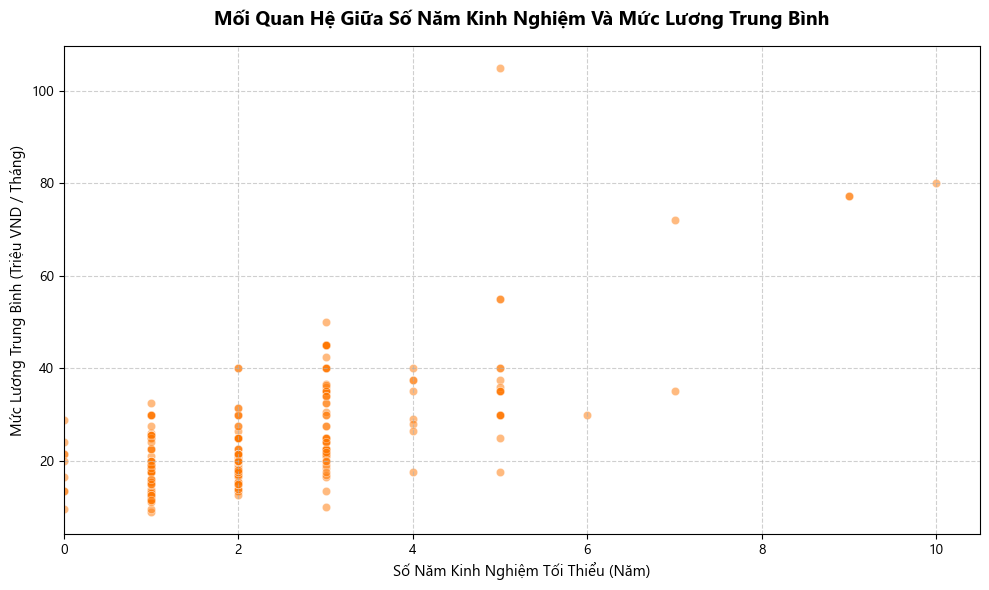

In [64]:
# 1. Cấu hình để vẽ biểu đồ hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI' # Hoặc 'Arial', 'Tahoma' tùy máy em
plt.figure(figsize=(10, 6))

# 2. Loại bỏ các dòng bị Null ở cả 2 cột để tránh lỗi đồ thị
df_plot = df.dropna(subset=['mean_salary', 'min_experience'])

# Mẹo quy đổi mức lương sang đơn vị "Triệu VND" cho trục tọa độ ngắn gọn, dễ nhìn
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


# 3. Vẽ b
sns.scatterplot(
    data=df_plot, 
    x='min_experience', 
    y='mean_salary_million', 
    alpha=0.5, # Độ trong suốt để nhìn rõ những chỗ các chấm đè lên nhau
    color="#ff7700"
)


# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học
plt.title('Mối Quan Hệ Giữa Số Năm Kinh Nghiệm Và Mức Lương Trung Bình', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số Năm Kinh Nghiệm Tối Thiểu (Năm)', fontsize=11)
plt.ylabel('Mức Lương Trung Bình (Triệu VND / Tháng)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6) # Thêm lưới mờ cho dễ dóng hàng

# Thới hạn hiển thị trục X gọn gàng từ 0 đến tối đa số năm kinh nghiệm thực tế trong data
plt.xlim(0, df_plot['min_experience'].max() + 0.5)

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_9440\1035102999.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


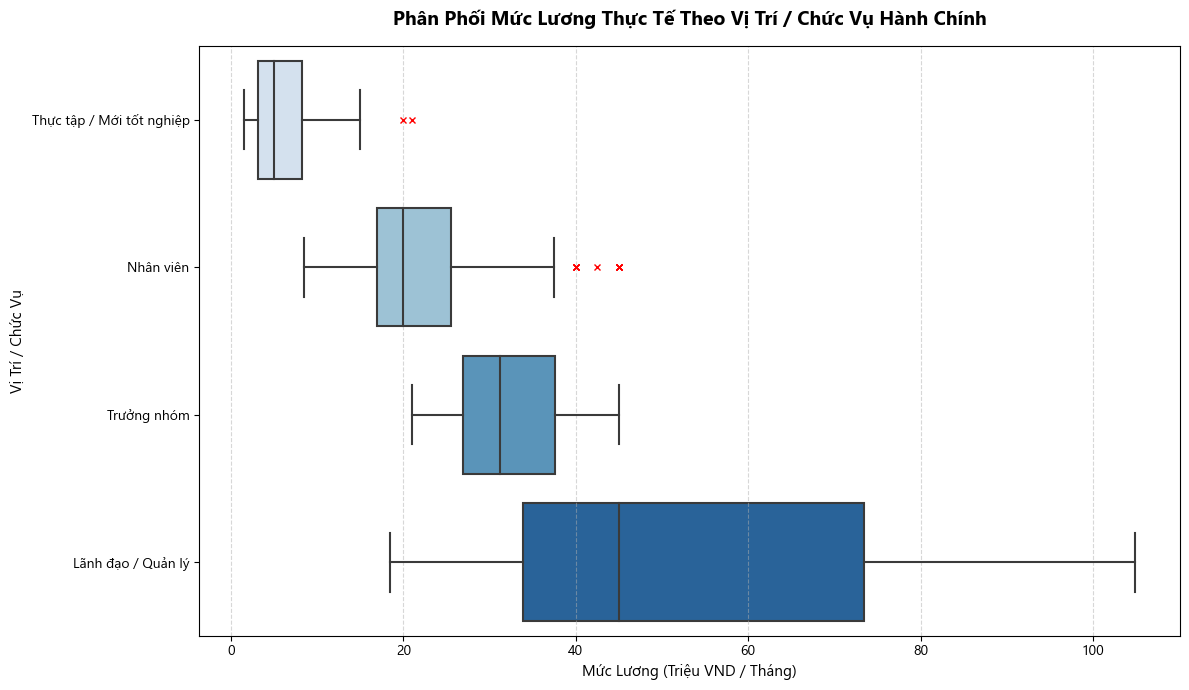

In [65]:
# LƯƠNG VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


## 2.7. posted_date DATE TIME

In [70]:
df['posted_date'].head(5)

0    27/03/2026
1    20/04/2026
2    10/04/2026
3    03/04/2026
4    13/04/2026
Name: posted_date, dtype: object

In [71]:
# 1. Chuyển đổi cột 'posted_date' sang kiểu datetime (nếu chưa có)
df['posted_date'] = pd.to_datetime(df['posted_date'])
df['posted_date'].head(5)

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_9440\2433232772.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_date'] = pd.to_datetime(df['posted_date'])


0   2026-03-27
1   2026-04-20
2   2026-04-10
3   2026-04-03
4   2026-04-13
Name: posted_date, dtype: datetime64[ns]

In [72]:
# Chuyển đổi trực tiếp 2 cột từ datetime sang chỉ lấy phần ngày (date)
df['posted_date'] = df['posted_date'].dt.date
df['posted_date'].value_counts().head(10)

posted_date
2026-04-23    51
2026-04-24    47
2026-04-22    43
2026-04-21    34
2026-04-20    32
2026-04-13    29
2026-04-26    28
2026-05-04    24
2026-05-15    22
2026-05-19    22
Name: count, dtype: int64

## 2.8. deadline_date DATE TIME

In [28]:
df['deadline_date'].head(5)

0    13/05/2026
1    30/06/2026
2    30/06/2026
3    08/05/2026
4    07/05/2026
Name: deadline_date, dtype: object

In [67]:
# 1. Chuyển đổi cột 'date_post' sang kiểu datetime (nếu chưa có)
df['deadline_date'] = pd.to_datetime(df['deadline_date'])
df['deadline_date'].head(5)

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_9440\2696961036.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['deadline_date'] = pd.to_datetime(df['deadline_date'])


0   2026-04-25
1   2026-05-04
2   2026-05-09
3   2026-05-02
4   2026-05-12
Name: deadline_date, dtype: datetime64[ns]

In [68]:
# Chuyển đổi trực tiếp 2 cột từ datetime sang chỉ lấy phần ngày (date)
df['deadline_date'] = df['deadline_date'].dt.date

df['deadline_date'].value_counts().head(10)

deadline_date
2026-06-30    91
2026-05-31    71
2026-04-30    46
2026-07-31    29
2026-05-12    28
2026-05-30    24
2026-06-15    23
2026-05-15    19
2026-05-04    19
2026-06-12    18
Name: count, dtype: int64

In [69]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['test', 'co_hien_thi_luong', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 
                      'salary_min', 'salary_max', 'mean_salary_no_unit'])

In [73]:
## 2. SAVED lần 3
df.to_csv("data_crviet_3.csv", index=False, encoding="utf-8-sig")